In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import constants

import networkx as nx
import MDAnalysis as mda
from MDAnalysis.analysis.distances import contact_matrix

plw = 0.6
pcs = 3
pms = 3
bfillc = [0.9,0.9,0.9]
plt.rcParams['axes.linewidth'] = plw
plt.rcParams['xtick.top'] = True
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['xtick.major.width'] = plw
plt.rcParams['xtick.minor.width'] = plw
plt.rcParams['xtick.minor.visible'] = True
plt.rcParams['xtick.major.size'] = 4.5
plt.rcParams['ytick.right'] = True
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['ytick.major.width'] = plw
plt.rcParams['ytick.minor.width'] = plw
plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['ytick.major.size'] = 5
plt.rcParams["figure.figsize"] = (5,4)

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "verdana"})
    #"font.verdana": ["computer modern roman"],
    #"font.size": 18})
    
SMALL_SIZE = 18
MEDIUM_SIZE = 18
BIGGER_SIZE = 18

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)    # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize

In [5]:
rmin_NaO=3.25 # approx 0.33 nm 
rmin_ClO=4.05 # approx 0.41 nm
N_threshold = 19 #COM-distance threshold to roughly label ions just around the crystal cluster 

In [10]:
#average=True
# ================= USER SETTINGS =================
top = "./md.tpr"             # or .gro/.pdb
traj = "./NaCl_8.xtc"        # or .trr/.xtc
stride = 1  #

# Na-Cl neighbor shell (nm); near first min of g_NaCl(r)
r_cut = 0.35                  # ~0.34-0.36 typical; tune from RDF

# nQ6 & CN guard (crystal test)
CN_MIN = 3                    # trust nQ6 only if CN >= CN_MIN
nq6_thresh = 0.2              # tune from your nQ6 histogram

# Surface = crystal + water-O contact (semi-interior but contacting O counts as surface)
r_w_Na = rmin_NaO/10          # 0.325 nm, Na-O cutoff (rmin_* in Å upstream)
r_w_Cl = rmin_ClO/10          # 0.405 nm, Cl-O cutoff
min_waters_Na = 3             # require >= this many O for Na
min_waters_Cl = 5             # require >= this many O for Cl

# Disordered ion distance split (from crystal center)
d0_disordered = N_threshold*0.1  # nm; ions within d0 -> "nearby"

# Outputs
out_with_waterO              = "q6_with_waterO.xyz"              # IONS ONLY; every 10 frames
out_with_waterO_every100     = "q6_with_waterO_every100.xyz"     # IONS + water O (label 6); every 100 frames
# Primary matrices (collapsed)
out_label_csv       = "label_matrix.csv"         # frames×ions: 0/1/2/3
out_label_npz       = "label_matrix.npz"
out_inCS_csv        = "in_cryst_surface.csv"     # frames×ions: 0/1 (crystal/surface OR nearby disordered = 1)
out_inCS_npz        = "in_cryst_surface.npz"
# Crystal-only (no nearby disordered)
out_inCrystal_csv   = "in_crystal_only.csv"      # frames×ions: 0/1 (crystal interior+surface = 1)
out_inCrystal_npz   = "in_crystal_only.npz"
# Crystal interior only (no surface, no disordered)
out_inInterior_csv  = "in_crystal_interior.csv"  # frames×ions: 0/1 (only labels 4/5 = 1)
out_inInterior_npz  = "in_crystal_interior.npz"
# Optional: detailed labels
out_labels_full_csv = "labels_full.csv"          # frames×ions: 0..6
out_labels_full_npz = "labels_full.npz"
# ==================================================

# ================= IMPORTS =================
import numpy as np
import MDAnalysis as mda
from freud import box as fbox, locality, order

# ----------------- Selectors -----------------
def select_ions(u_freq: mda.Universe):
    ions = u_freq.select_atoms("name NA or name NAs or name CL or name CLs")
    if len(ions) == 0:
        raise ValueError("No ions found with names NA/NAs/CL/CLs.")
    names = np.asarray(ions.names, dtype=str)
    names_upper = np.char.upper(names)
    mask_na = np.char.startswith(names_upper, "NA")
    species = np.where(mask_na, "Na", "Cl")
    return ions, species

def select_water_oxygens(u_freq: mda.Universe):
    return u_freq.select_atoms("name OW")

# ----------------- Helpers (triclinic-safe) -----------------
def freud_box_from_ts(ts):
    A = getattr(ts, "triclinic_dimensions", None)
    if A is not None and np.all(np.isfinite(A)):
        return fbox.Box.from_matrix(A * 0.1)  # Å -> nm
    Lx, Ly, Lz, a, b, g = ts.dimensions
    return fbox.Box.from_box([Lx*0.1, Ly*0.1, Lz*0.1, a, b, g])

def cell_matrix_from_dimensions_nm(ts):
    Lx, Ly, Lz, alpha, beta, gamma = ts.dimensions
    Lx, Ly, Lz = Lx*0.1, Ly*0.1, Lz*0.1
    a = np.deg2rad(alpha); b = np.deg2rad(beta); g = np.deg2rad(gamma)
    cos_a, cos_b, cos_g = np.cos(a), np.cos(b), np.cos(g)
    sin_g = np.sin(g)
    H = np.zeros((3,3), dtype=float)
    H[0,0] = Lx
    H[0,1] = Ly * cos_g
    H[1,1] = Ly * sin_g
    H[0,2] = Lz * cos_b
    H[1,2] = Lz * (cos_a - cos_b * cos_g) / max(sin_g, 1e-12)
    term = 1.0 - cos_b**2 - ((cos_a - cos_b*cos_g)/max(sin_g,1e-12))**2
    H[2,2] = Lz * np.sqrt(max(term, 0.0))
    Hinv = np.linalg.inv(H)
    return H, Hinv

def to_fractional(pos_nm, Hinv): return pos_nm @ Hinv.T
def to_real(frac, H): return frac @ H.T
def wrap_frac(frac): return frac - np.floor(frac)
def min_image_frac(df): return df - np.rint(df)

def wrap_real(pos_nm, H, Hinv):
    s = to_fractional(pos_nm, Hinv)
    s_wrapped = wrap_frac(s)
    return to_real(s_wrapped, H)

def unwrap_cluster_fractional(frac_all, cluster_mask, nlist):
    cluster_indices = np.where(cluster_mask)[0]
    Nc = cluster_indices.size
    if Nc == 0:
        return np.zeros((0,3), dtype=float), cluster_indices

    i_all = nlist.point_indices
    j_all = nlist.query_point_indices
    mask_edges = cluster_mask[i_all] & cluster_mask[j_all]
    i = i_all[mask_edges]
    j = j_all[mask_edges]

    # FIXED: ensure dtype specified correctly
    loc_index = -np.ones(frac_all.shape[0], dtype=int)
    loc_index[cluster_indices] = np.arange(Nc, dtype=int)

    neighbors_local = [[] for _ in range(Nc)]
    for a, b in zip(i, j):
        la, lb = loc_index[a], loc_index[b]
        if la >= 0 and lb >= 0:
            neighbors_local[la].append(lb)
            neighbors_local[lb].append(la)

    from collections import deque
    frac_unwrapped = np.zeros((Nc,3), dtype=float)
    visited = np.zeros(Nc, dtype=bool)
    root = 0
    visited[root] = True
    frac_unwrapped[root] = frac_all[cluster_indices[root]]
    q = deque([root])
    while q:
        li = q.popleft()
        gi = cluster_indices[li]
        for lb in neighbors_local[li]:
            if visited[lb]:
                continue
            gj = cluster_indices[lb]
            df = frac_all[gj] - frac_all[gi]
            df = min_image_frac(df)
            frac_unwrapped[lb] = frac_unwrapped[li] + df
            visited[lb] = True
            q.append(lb)
    return frac_unwrapped, cluster_indices

def build_nlist_nacl(box, pos_nm, rcut_nm, species_ions):
    q = locality.AABBQuery(box, pos_nm)
    nl_all = q.query(pos_nm, {"r_max": rcut_nm, "exclude_ii": True}).toNeighborList()
    i = nl_all.point_indices; j = nl_all.query_point_indices; d = nl_all.distances
    keep = (species_ions[i] != species_ions[j])
    if keep.sum() == 0: return nl_all
    return locality.NeighborList.from_arrays(
        len(pos_nm), len(pos_nm),
        j[keep].astype(np.uint32),
        i[keep].astype(np.uint32),
        d[keep].astype(np.float32)
    )

def compute_nq6(box, pos_nm, nlist):
    st = order.Steinhardt(l=6, average=True, weighted=False)
    st.compute((box, pos_nm), neighbors=nlist)
    return np.asarray(st.particle_order)

def largest_crystal_component_mask(nlist, crystal_mask, N):
    parent = np.arange(N, dtype=np.int32)
    size   = np.ones(N, dtype=np.int32)
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb: return
        if size[ra] < size[rb]: ra, rb = rb, ra
        parent[rb] = ra; size[ra]  += size[rb]
    i = nlist.point_indices; j = nlist.query_point_indices
    mask = crystal_mask[i] & crystal_mask[j]
    ii = i[mask].astype(np.int32, copy=False); jj = j[mask].astype(np.int32, copy=False)
    for a, b in zip(ii, jj): union(a, b)
    roots = np.array([find(k) for k in range(N)], dtype=np.int32)
    roots[~crystal_mask] = -1
    vals, counts = np.unique(roots[roots >= 0], return_counts=True)
    if len(vals) == 0: return np.zeros(N, dtype=bool)
    largest_root = vals[np.argmax(counts)]
    return (roots == largest_root) & crystal_mask

# --------------- MAIN ---------------
u_freq = mda.Universe(top, traj)
ions, sp_ions = select_ions(u_freq)
watO = select_water_oxygens(u_freq)

label_rows_3 = []
inCS_rows = []
inCrystal_rows = []
inInterior_rows = []  # interior only (labels 4/5)
labels_full_rows = []
frame_ids = []

all_CN = []
all_nq6_guard = []

with open(out_with_waterO, "w") as f_waterO, open(out_with_waterO_every100, "w") as f_waterO_full:
    step_idx = 0
    for ts in u_freq.trajectory[::stride]:
        step_idx += 1
        pos_nm_ions = ions.positions.astype(float) * 0.1
        H, Hinv = cell_matrix_from_dimensions_nm(ts)
        box = freud_box_from_ts(ts)

        # Na–Cl neighbor list & CN
        nlist = build_nlist_nacl(box, pos_nm_ions, r_cut, sp_ions)
        j = nlist.query_point_indices
        CN = np.bincount(j, minlength=len(ions))

        # nQ6 with CN guard
        nq6 = compute_nq6(box, pos_nm_ions, nlist)
        nq6_guard = np.where(CN >= CN_MIN, np.nan_to_num(nq6, nan=0.0), 0.0)
        all_CN.extend(CN.tolist())
        all_nq6_guard.extend(nq6_guard.tolist())

        # Crystal candidacy & largest component
        crystal_mask_all = (nq6_guard >= nq6_thresh)
        in_largest = largest_crystal_component_mask(nlist, crystal_mask_all, len(ions))
        crystal_inL = in_largest

        # Water-contact counting
        if len(watO) > 0:
            pos_nm_w = watO.positions.astype(float) * 0.1
            r_w_max = max(r_w_Na, r_w_Cl)
            q_w = locality.AABBQuery(box, pos_nm_w)
            nl_w = q_w.query(pos_nm_ions, {"r_max": r_w_max, "exclude_ii": False}).toNeighborList()
            jw = nl_w.query_point_indices; dw = nl_w.distances
            is_na = (sp_ions == "Na"); is_cl = ~is_na
            mask_na = is_na[jw] & (dw <= r_w_Na)
            mask_cl = is_cl[jw] & (dw <= r_w_Cl)
            water_cnt = np.bincount(jw[mask_na], minlength=len(ions)) \
                      + np.bincount(jw[mask_cl], minlength=len(ions))
            touch_water = np.zeros(len(ions), dtype=bool)
            touch_water[is_na] = (water_cnt[is_na] >= min_waters_Na)
            touch_water[is_cl] = (water_cnt[is_cl] >= min_waters_Cl)
        else:
            is_na = (sp_ions == "Na"); is_cl = ~is_na
            touch_water = np.zeros(len(ions), dtype=bool)

        # Assign crystal labels
        labels_full = np.full(len(ions), -1, dtype=int)
        inCS_row = crystal_inL.astype(int).copy()
        inCrystal_row = crystal_inL.astype(int).copy()

        bulk_mask    = crystal_inL & (~touch_water)
        surface_mask = crystal_inL & ( touch_water)

        labels_full[np.where(surface_mask & is_na)] = 2  # surface Na
        labels_full[np.where(surface_mask & is_cl)] = 3  # surface Cl
        labels_full[np.where(bulk_mask    & is_na)] = 4  # bulk Na (interior)
        labels_full[np.where(bulk_mask    & is_cl)] = 5  # bulk Cl (interior)

        # Determine center (unwrapped)
        frac_all = to_fractional(pos_nm_ions, Hinv)
        frac_unw, cluster_idx = unwrap_cluster_fractional(frac_all, crystal_inL, nlist)

        if np.any(bulk_mask):
            cl_local = {g: k for k, g in enumerate(cluster_idx)}
            bulk_globals = np.where(bulk_mask)[0]
            bulk_locals = [cl_local[g] for g in bulk_globals if g in cl_local]
            if len(bulk_locals) > 0:
                center_nm = to_real(frac_unw[bulk_locals].mean(axis=0), H)
            else:
                center_nm = to_real(frac_unw.mean(axis=0), H) if frac_unw.shape[0] > 0 else to_real(wrap_frac(frac_all).mean(axis=0), H)
        elif frac_unw.shape[0] > 0:
            center_nm = to_real(frac_unw.mean(axis=0), H)
        else:
            center_nm = to_real(wrap_frac(frac_all).mean(axis=0), H)

        # Disordered labels via distance to center
        not_crystal = ~crystal_inL
        if np.any(not_crystal):
            s_all = frac_all
            s_ctr = to_fractional(center_nm.reshape(1,3), Hinv)[0]
            ds = s_all[not_crystal] - s_ctr
            ds = min_image_frac(ds)
            dr = to_real(ds, H)
            r_nm = np.linalg.norm(dr, axis=1)
            inner = (r_nm <= d0_disordered)
            idxs  = np.where(not_crystal)[0]
            labels_full[idxs[inner]]  = 0  # nearby disordered
            labels_full[idxs[~inner]] = 1  # far disordered
            inCS_row[idxs[inner]] = 1      # nearby disordered counted as "in crystal/surface neighborhood"
        labels_full[labels_full < 0] = 1

        # Interior-only mask (labels 4/5)
        inInterior_row = np.isin(labels_full, [4, 5]).astype(int)

        # Collapsed labels (0 far, 1 nearby, 2 surface, 3 bulk)
        labels_3 = np.zeros(len(ions), dtype=int)
        labels_3[np.isin(labels_full, [4, 5])] = 3
        labels_3[np.isin(labels_full, [2, 3])] = 2
        labels_3[np.isin(labels_full, [0])]    = 1

        # Accumulate matrices
        label_rows_3.append(labels_3.astype(int))
        inCS_rows.append(inCS_row.astype(int))
        inCrystal_rows.append(inCrystal_row.astype(int))
        inInterior_rows.append(inInterior_row.astype(int))
        labels_full_rows.append(labels_full.astype(int))
        frame_ids.append(ts.frame)

        # Recentering for XYZ output (ions + optional waters)
        if len(watO) > 0:
            pos_nm_all = np.vstack([pos_nm_ions, (watO.positions.astype(float) * 0.1)])
        else:
            pos_nm_all = pos_nm_ions.copy()
        r_box_center = to_real(np.array([[0.5, 0.5, 0.5]]), H)[0]
        shifted_nm = pos_nm_all - center_nm + r_box_center
        wrapped_nm = wrap_real(shifted_nm, H, Hinv)

        # ---- IONS-ONLY XYZ: write every 10 processed frames ----
        if step_idx % 10 == 0:
            coords_ionsA_centered = (wrapped_nm[:len(ions)] * 10.0)
            lines = [
                f"{len(ions)}\n",
                f"frame={ts.frame}\n",
                *[
                    f"{elem} {xyz[0]:.6f} {xyz[1]:.6f} {xyz[2]:.6f} {lab}\n"
                for elem, xyz, lab in zip(sp_ions, coords_ionsA_centered, labels_full)
                    ],
            ]
            f_waterO.write(''.join(lines))

        # ---- IONS + WATER-O XYZ: write every 100 processed frames (waters labeled 6) ----
        if len(watO) > 0 and (step_idx % 100 == 0):
            coords_all_A_centered = (wrapped_nm * 10.0)  # ions + waters
            species_all = np.concatenate([sp_ions, np.array(["O"] * len(watO))])
            labels_all  = np.concatenate([labels_full, np.full(len(watO), 6, dtype=int)])

            n_all = coords_all_A_centered.shape[0]
            lines_full = [
                f"{n_all}\n",
                f"frame={ts.frame}\n",
                *[
                    f"{elem} {xyz[0]:.6f} {xyz[1]:.6f} {xyz[2]:.6f} {lab}\n"
                    for elem, xyz, lab in zip(species_all, coords_all_A_centered, labels_all)
                ],
            ]
            f_waterO_full.write(''.join(lines_full))

# ---------- Save matrices ----------
label_matrix       = np.vstack(label_rows_3)
inCS_matrix        = np.vstack(inCS_rows)
inCrystal_matrix   = np.vstack(inCrystal_rows)
inInterior_matrix  = np.vstack(inInterior_rows)
labels_full_matrix = np.vstack(labels_full_rows)

header_main = ",".join([f"ion_{k}" for k in range(label_matrix.shape[1])])
#np.savetxt(out_label_csv, label_matrix, fmt="%d", delimiter=",", header=header_main, comments="")
#np.savez(out_label_npz, labels=label_matrix, frames=np.array(frame_ids), species=np.array(sp_ions))

header_incs = ",".join([f"ion_{k}" for k in range(inCS_matrix.shape[1])])
#np.savetxt(out_inCS_csv, inCS_matrix, fmt="%d", delimiter=",", header=header_incs, comments="")
#np.savez(out_inCS_npz, in_cryst_surface=inCS_matrix, frames=np.array(frame_ids), species=np.array(sp_ions))

header_incrystal = ",".join([f"ion_{k}" for k in range(inCrystal_matrix.shape[1])])
#np.savetxt(out_inCrystal_csv, inCrystal_matrix, fmt="%d", delimiter=",", header=header_incrystal, comments="")
#np.savez(out_inCrystal_npz, in_crystal_only=inCrystal_matrix, frames=np.array(frame_ids), species=np.array(sp_ions))

header_interior = ",".join([f"ion_{k}" for k in range(inInterior_matrix.shape[1])])
#np.savetxt(out_inInterior_csv, inInterior_matrix, fmt="%d", delimiter=",", header=header_interior, comments="")
#np.savez(out_inInterior_npz, in_crystal_interior=inInterior_matrix, frames=np.array(frame_ids), species=np.array(sp_ions))

header_full = ",".join([f"ion_{k}" for k in range(labels_full_matrix.shape[1])])
#np.savetxt(out_labels_full_csv, labels_full_matrix, fmt="%d", delimiter=",", header=header_full, comments="")
#np.savez(out_labels_full_npz, labels=labels_full_matrix, frames=np.array(frame_ids), species=np.array(sp_ions))

print(
    "Done.\n"
    f"  Ions XYZ (every 10)                   : {out_with_waterO}\n"
    f"  Ions+Water XYZ (every 100)            : {out_with_waterO_every100}\n"
    f"  label_matrix CSV                      : {out_label_csv}     (shape {label_matrix.shape}, values 0/1/2/3)\n"
    f"  label_matrix NPZ                      : {out_label_npz}\n"
    f"  in_cryst_surface CSV                  : {out_inCS_csv}      (shape {inCS_matrix.shape}, values 0/1)\n"
    f"  in_cryst_surface NPZ                  : {out_inCS_npz}\n"
    f"  in_crystal_only CSV                   : {out_inCrystal_csv} (shape {inCrystal_matrix.shape}, values 0/1)\n"
    f"  in_crystal_only NPZ                   : {out_inCrystal_npz}\n"
    f"  in_crystal_interior CSV               : {out_inInterior_csv} (shape {inInterior_matrix.shape}, values 0/1)\n"
    f"  in_crystal_interior NPZ               : {out_inInterior_npz}\n"
    f"  labels_full CSV                       : {out_labels_full_csv} (shape {labels_full_matrix.shape}, values 0..6)\n"
    f"  labels_full NPZ                       : {out_labels_full_npz}"
)

Done.
  Ions XYZ (every 10)                   : q6_with_waterO.xyz
  Ions+Water XYZ (every 100)            : q6_with_waterO_every100.xyz
  label_matrix CSV                      : label_matrix.csv     (shape (83, 1202), values 0/1/2/3)
  label_matrix NPZ                      : label_matrix.npz
  in_cryst_surface CSV                  : in_cryst_surface.csv      (shape (83, 1202), values 0/1)
  in_cryst_surface NPZ                  : in_cryst_surface.npz
  in_crystal_only CSV                   : in_crystal_only.csv (shape (83, 1202), values 0/1)
  in_crystal_only NPZ                   : in_crystal_only.npz
  in_crystal_interior CSV               : in_crystal_interior.csv (shape (83, 1202), values 0/1)
  in_crystal_interior NPZ               : in_crystal_interior.npz
  labels_full CSV                       : labels_full.csv (shape (83, 1202), values 0..6)
  labels_full NPZ                       : labels_full.npz


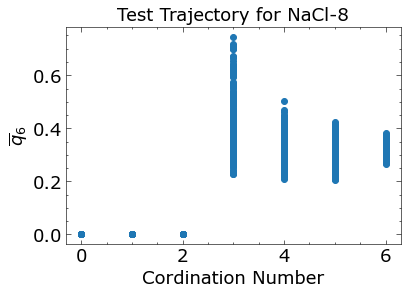

In [11]:
plt.scatter(all_CN,all_nq6_guard)
plt.title("Test Trajectory for NaCl-8")
plt.xlabel("Cordination Number")
plt.ylabel(r"$\overline{q}_6$")
plt.show()